# Baseline Sentiment Classification

Train comparable TF-IDF baselines using Logistic Regression, Naive Bayes and Linear SVM. Using validation data for model selection and reserve the test set for final evaluation.

In [13]:
# import all libraries
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    classification_report, ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt
import joblib

### Load and validate the cleaned dataset

In [3]:
cleaned_data = pd.read_csv("../dataset/cleaned_data/cleaned_montra_data.csv")
LABELS = ["negative", "neutral", "positive"]

cleaned_data["sentiment_label"] = (cleaned_data["sentiment_label"].astype(str).str.lower().str.strip())
cleaned_data = cleaned_data[cleaned_data["heavy_text"].notna()
    & cleaned_data["heavy_text"].astype(str).str.strip().ne("")
    & cleaned_data["sentiment_label"].isin(LABELS)].copy()

print(cleaned_data["sentiment_label"].value_counts())

sentiment_label
neutral     13355
positive    11782
negative     9863
Name: count, dtype: int64


## Create train, validation and test splits

In [ ]:
# Split ratio 60% train, 20% validation, 20% test.
# splitting for train dataset
train_df, temp_df = train_test_split(cleaned_data, test_size=0.40, random_state=42, stratify=cleaned_data["sentiment_label"])
# splitting for validation and test dataset
valid_df, test_df = train_test_split(temp_df, test_size=0.50, random_state=42, stratify=temp_df["sentiment_label"])

# summary of the split dataset(X_train, X-Valid, X_Test)
X_train, y_train = train_df["heavy_text"], train_df["sentiment_label"]
X_valid, y_valid = valid_df["heavy_text"], valid_df["sentiment_label"]
X_test, y_test = test_df["heavy_text"], test_df["sentiment_label"]

# split data output
print(f'Train Data: {len(train_df)}, \nValidation Data: {len(valid_df)},\nTest Data: {len(test_df)}')

Train Data: 21000, 
Validation Data: 7000,
Test Data: 7000


## Train and compare baseline models

In [20]:
# Define the models
base_models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=1, class_weight="balanced"),
    "Naive Bayes": MultinomialNB(),
    "Linear SVM": LinearSVC(class_weight="balanced" )}

# Create empty containers
fitted_models = {}
validation_results = []

# Train and evaluate each model
for name, classifier in base_models.items():

    # pipepline to convert review text into TF-IDF features and build the model
    pipeline = Pipeline([(
        "tfidf", TfidfVectorizer(max_features=20000, ngram_range=(1, 2))),
        ("classifier", classifier)])

    # Train the model on train set
    pipeline.fit(X_train, y_train)

    # Predict sentiment labels
    pred = pipeline.predict(X_valid)

    # Calculate validation metrics
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_valid, pred,
        labels=LABELS, average="macro",
        zero_division=0)

    # Store the results
    validation_results.append({
        "Base Models": name,
        "Accuracy": accuracy_score(y_valid, pred),
        "Macro Precision": precision,
        "Macro Recall": recall,
        "Macro F1": f1})

    # Store the trained pipeline
    fitted_models[name] = pipeline

# 4. Display models from best to worst by Macro F1
validation_results = (pd.DataFrame(validation_results).sort_values("Macro F1", ascending=False)
    .round(4).reset_index(drop=True))

display(validation_results)


,Base Models,Accuracy,Macro Precision,Macro Recall,Macro F1
0,Random Forest,0.9397,0.9428,0.9400,0.9412
1,Logistic Regression,0.9393,0.9432,0.9390,0.9408
2,Linear SVM,0.9369,0.9413,0.9365,0.9385
3,Naive Bayes,0.9319,0.9378,0.9308,0.9336


## Select model using validation macro-F1

Selected baseline: Random Forest
              precision    recall  f1-score   support

    negative       0.96      0.93      0.95      1972
     neutral       0.90      0.94      0.92      2671
    positive       0.96      0.94      0.95      2357

    accuracy                           0.94      7000
   macro avg       0.94      0.94      0.94      7000
weighted avg       0.94      0.94      0.94      7000



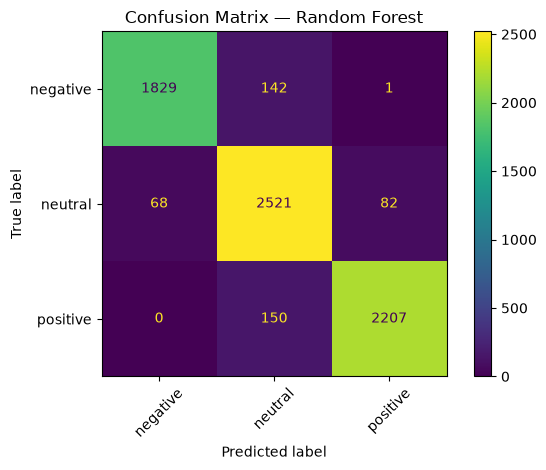

In [21]:
best_name = validation_results.iloc[0]["Base Models"]
best_model = fitted_models[best_name]
print("Selected baseline:", best_name)

# Evaluate the selected baseline once on the held-out test set.
test_pred = best_model.predict(X_test)
print(classification_report(y_test, test_pred, labels=LABELS, zero_division=0))

# print confusion matrix
ConfusionMatrixDisplay.from_predictions(y_test, test_pred, labels=LABELS, xticks_rotation=45)
plt.title(f"Confusion Matrix — {best_name}")
plt.tight_layout()
plt.show()

## Save model and test predictions

In [23]:
OUT = Path("../Model/baseline")
OUT.mkdir(parents=True, exist_ok=True)
joblib.dump(best_model, OUT / "best_baseline_pipeline.joblib")

predictions = test_df.copy()
predictions["predicted_sentiment"] = test_pred
predictions.to_csv("../Dataset/modelled_data/baseline_test_predictions.csv", index=False)
validation_results.to_csv("../Results/reports_baseline_validation.csv", index=False)
print("Saved baseline model and predictions.")

Saved baseline model and predictions.
